In [1]:
import glob
import pandas as pd
import textwrap
import matplotlib.pyplot as plt
%matplotlib inline

folder = '/kaggle/input/datasets/bhanuprasadspirit/owid-co2'
csv_files = glob.glob(folder + '/**/*.csv', recursive=True)
print("CSV files found:", csv_files)

raw = pd.read_csv(csv_files[0])

countries = ['United States','China','India','Germany','United Kingdom','France','Brazil',
             'Japan','Canada','Australia','South Korea','Russia','South Africa','Mexico','Indonesia']
region_map = {'United States':'North America','Canada':'North America','Mexico':'North America',
              'China':'Asia','India':'Asia','Japan':'Asia','South Korea':'Asia','Indonesia':'Asia',
              'Russia':'Europe','Germany':'Europe','United Kingdom':'Europe','France':'Europe',
              'Brazil':'Latin America','South Africa':'Africa','Australia':'Oceania'}

df = raw[raw['country'].isin(countries) & raw['year'].between(2000, 2022)].copy()
df = df.rename(columns={'country':'Country','year':'Year','co2':'CO2_Mt','co2_per_capita':'CO2_per_capita'})
df['Region'] = df['Country'].map(region_map)
df = df[['Country','Region','Year','CO2_Mt','CO2_per_capita']]

print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())

CSV files found: ['/kaggle/input/datasets/bhanuprasadspirit/owid-co2/owid-co2-data.csv']
Loaded: 345 rows | Countries: 15 | Years: 2000-2022
        Country   Region  Year   CO2_Mt  CO2_per_capita
3654  Australia  Oceania  2000  349.898          18.288
3655  Australia  Oceania  2001  357.668          18.469
3656  Australia  Oceania  2002  362.425          18.495
3657  Australia  Oceania  2003  370.784          18.708
3658  Australia  Oceania  2004  382.005          19.056


In [2]:
print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))

Countries: ['Australia' 'Brazil' 'Canada' 'China' 'France' 'Germany' 'India'
 'Indonesia' 'Japan' 'Mexico' 'Russia' 'South Africa' 'South Korea'
 'United Kingdom' 'United States']

CO2 range: 281.054 to 11711.808 Mt

Regional averages (2022):
Region
Asia             3387.5
North America    2019.0
Europe            737.4
Latin America     480.1
Africa            428.8
Oceania           384.1
Name: CO2_Mt, dtype: float64


In [3]:
GREY = '#EEEEEE'
COLOR = '#D62728'

def highlight_chart(data, value_col, highlight, title, ytitle):
    fig, ax = plt.subplots(figsize=(9.5, 5.2), dpi=150)
    for c in data['Country'].unique():
        if c == highlight:
            continue
        d = data[data['Country'] == c].sort_values('Year')
        ax.plot(d['Year'], d[value_col], color=GREY, linewidth=1)
    h = data[data['Country'] == highlight].sort_values('Year')
    ax.plot(h['Year'], h[value_col], color=COLOR, linewidth=3.5)
    ax.annotate(highlight, (h['Year'].iloc[-1], h[value_col].iloc[-1]),
                xytext=(8, 0), textcoords='offset points', va='center',
                color=COLOR, fontsize=13, fontweight='bold', annotation_clip=False)
    for s in ['top', 'right', 'left', 'bottom']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#F2F2F2', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, colors='#555555')
    ax.set_xticks(range(int(data['Year'].min()), int(data['Year'].max()) + 1, 2))
    ax.set_ylabel(ytitle, color='#555555')
    fig.suptitle(textwrap.fill(title, 80), x=0.01, ha='left', fontsize=14, fontweight='bold')
    fig.subplots_adjust(left=0.08, right=0.9, top=0.82, bottom=0.08)
    return fig

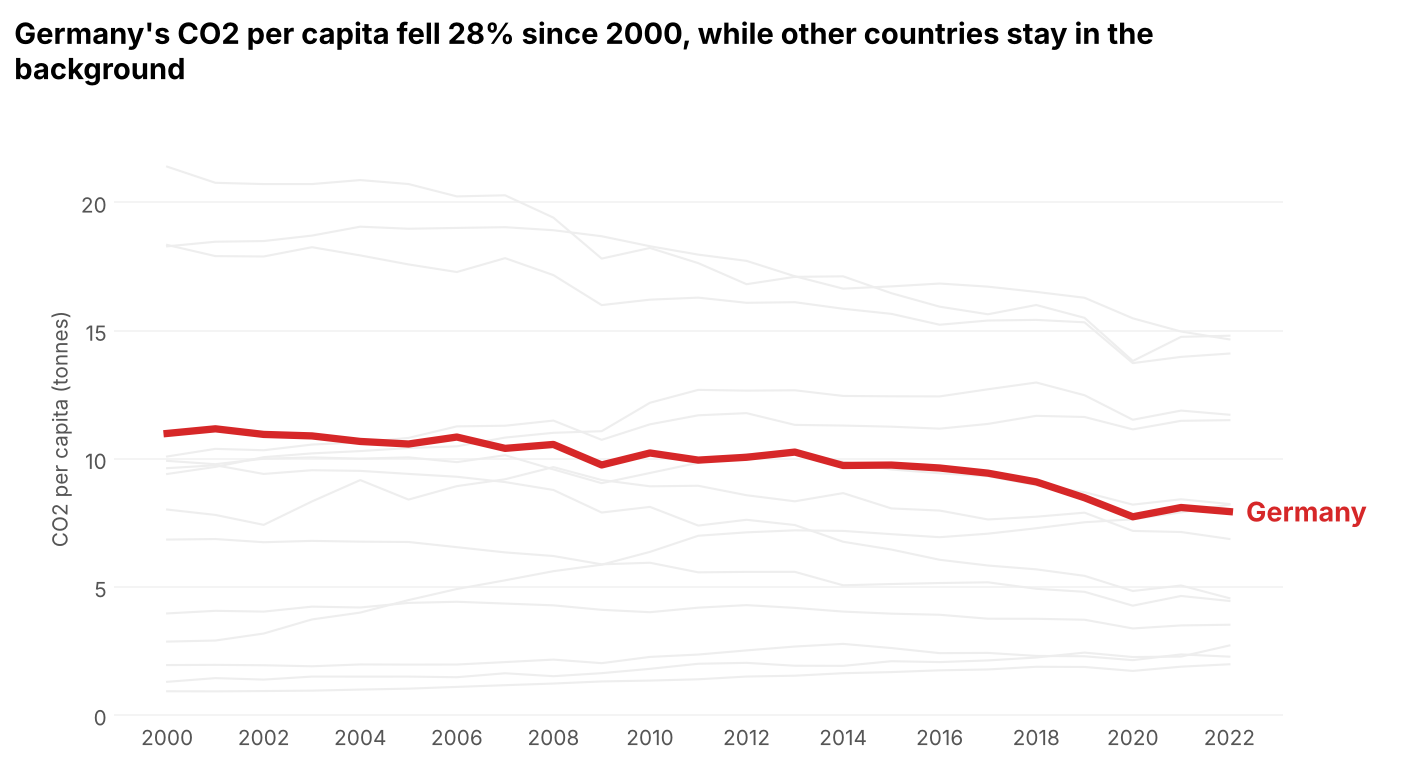

In [4]:
d1 = df.dropna(subset=['CO2_per_capita'])
g = d1[d1['Country'] == 'Germany'].sort_values('Year')
change = (g['CO2_per_capita'].iloc[-1] / g['CO2_per_capita'].iloc[0] - 1) * 100
direction = "fell" if change < 0 else "rose"

fig1 = highlight_chart(
    d1, 'CO2_per_capita', 'Germany',
    f"Germany's CO2 per capita {direction} {abs(change):.0f}% since {g['Year'].iloc[0]}, while other countries stay in the background",
    'CO2 per capita (tonnes)'
)
plt.show()

Asian countries: ['China' 'India' 'Indonesia' 'Japan' 'South Korea']


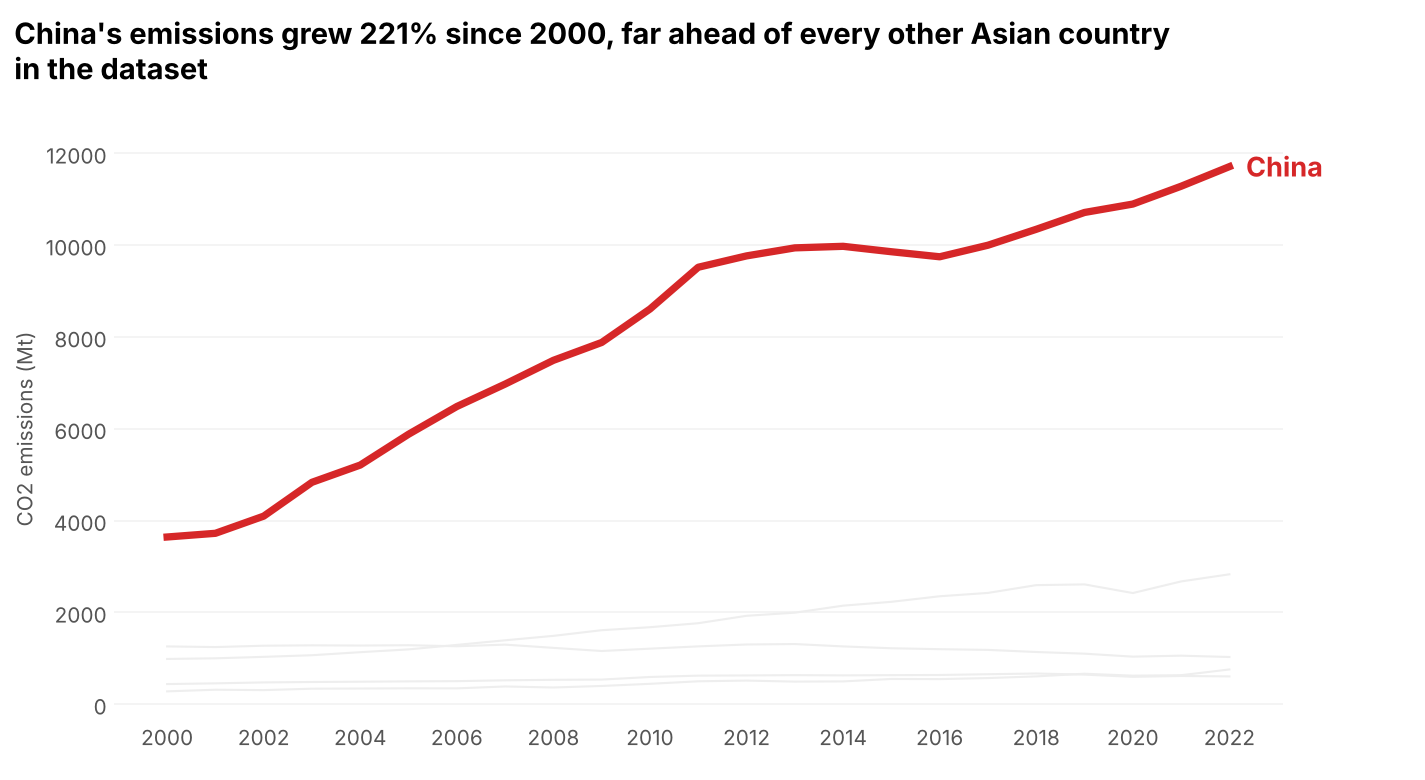

In [5]:
asia = df[df['Region'] == 'Asia'].dropna(subset=['CO2_Mt'])
print("Asian countries:", asia['Country'].unique())

c = asia[asia['Country'] == 'China'].sort_values('Year')
growth = (c['CO2_Mt'].iloc[-1] / c['CO2_Mt'].iloc[0] - 1) * 100

fig2 = highlight_chart(
    asia, 'CO2_Mt', 'China',
    f"China's emissions grew {growth:.0f}% since {c['Year'].iloc[0]}, far ahead of every other Asian country in the dataset",
    'CO2 emissions (Mt)'
)
plt.show()